# 04b — P2 Head Ablation (custom architecture)

Two runs from `yolo-e1_best.pt` that differ only in the detection head: P3–P5 (control) vs P2–P5. Same data (`k5_drop_L1920`), imgsz 1280, 1.5 GPU-h, batch 2, seed 42, LR warm-up 0.5 epoch.

In [1]:
import os, sys
from pathlib import Path

if Path.cwd().name == "notebooks":          # always run from the repository root
    os.chdir(Path.cwd().parent)
sys.path.insert(0, str(Path("src").resolve()))  # use the local `vdet` package even without `pip install -e .`

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from vdet.paths import P
from vdet.notebook import *   # setup_notebook, results_table, show_image, *_experiment, evaluate_preds, ...

setup_notebook(seed=42)

# Training cells are resumable: a run whose checkpoint already exists in checkpoints/ is not
# trained again (its training log and metrics are loaded). Delete the checkpoint to retrain.

Project root : /home/marko/ucu-ai-hw-2
Data         : /home/marko/ucu-ai-hw-2/data (exists=True)
Cache        : /home/marko/ucu-ai-hw-2/cache (exists=True)
Checkpoints  : /home/marko/ucu-ai-hw-2/checkpoints
Device       : NVIDIA GeForce RTX 4050 Laptop GPU


In [2]:
from vdet.config import write_model_yaml

AUG = dict(hflip=0.5, vflip=0.0, degrees=0.0, scale_min=0.5, hsv_h=0.015, hsv_s=0.4, hsv_v=0.3)
INF = dict(conf_thresh=0.001, nms_iou=0.6, max_det=500, slim_conf_thresh=0.05)

YOLO11S_P2_YAML = """
nc: 8
scale: s
scales:
  n: [0.50, 0.25, 1024]
  s: [0.50, 0.50, 1024]
  m: [0.50, 1.00, 512]
backbone:
  - [-1, 1, Conv, [64, 3, 2]] # 0-P1/2
  - [-1, 1, Conv, [128, 3, 2]] # 1-P2/4
  - [-1, 2, C3k2, [256, False, 0.25]] # 2
  - [-1, 1, Conv, [256, 3, 2]] # 3-P3/8
  - [-1, 2, C3k2, [512, False, 0.25]] # 4
  - [-1, 1, Conv, [512, 3, 2]] # 5-P4/16
  - [-1, 2, C3k2, [512, True]] # 6
  - [-1, 1, Conv, [1024, 3, 2]] # 7-P5/32
  - [-1, 2, C3k2, [1024, True]] # 8
  - [-1, 1, SPPF, [1024, 5]] # 9
  - [-1, 2, C2PSA, [1024]] # 10
head:
  - [-1, 1, nn.Upsample, [None, 2, "nearest"]]
  - [[-1, 6], 1, Concat, [1]] # cat backbone P4
  - [-1, 2, C3k2, [512, False]] # 13
  - [-1, 1, nn.Upsample, [None, 2, "nearest"]]
  - [[-1, 4], 1, Concat, [1]] # cat backbone P3
  - [-1, 2, C3k2, [256, False]] # 16 (P3/8)
  - [-1, 1, nn.Upsample, [None, 2, "nearest"]]
  - [[-1, 2], 1, Concat, [1]] # cat backbone P2
  - [-1, 2, C3k2, [128, False]] # 19 (P2/4-tiny)
  - [-1, 1, Conv, [128, 3, 2]]
  - [[-1, 16], 1, Concat, [1]] # cat head P3
  - [-1, 2, C3k2, [256, False]] # 22 (P3/8-small)
  - [-1, 1, Conv, [256, 3, 2]]
  - [[-1, 13], 1, Concat, [1]] # cat head P4
  - [-1, 2, C3k2, [512, False]] # 25 (P4/16-medium)
  - [-1, 1, Conv, [512, 3, 2]]
  - [[-1, 10], 1, Concat, [1]] # cat head P5
  - [-1, 2, C3k2, [1024, True]] # 28 (P5/32-large)
  - [[19, 22, 25, 28], 1, Detect, [nc]] # Detect(P2, P3, P4, P5)
"""
P2_YAML_PATH = str(write_model_yaml("yolo11s-p2.yaml", YOLO11S_P2_YAML))

## 1. Architecture: parameters and detection grids

In [3]:
from ultralytics import YOLO
for name, spec in [("YOLO11s (P3-P5)", "yolo11s.yaml"), ("YOLO11s-P2 (P2-P5)", P2_YAML_PATH)]:
    m = YOLO(spec).model
    n_params = sum(p.numel() for p in m.parameters())
    strides = [int(s) for s in m.model[-1].stride.tolist()]
    cells = sum((1280 // s) ** 2 for s in strides)
    print(f"{name:20s} params = {n_params / 1e6:.2f} M | detect strides = {strides} | prediction cells @1280 = {cells:,}")

YOLO11s (P3-P5)      params = 9.46 M | detect strides = [8, 16, 32] | prediction cells @1280 = 33,600


YOLO11s-P2 (P2-P5)   params = 9.58 M | detect strides = [4, 8, 16, 32] | prediction cells @1280 = 136,000


## 2. Training both arms

In [4]:
ABL_COMMON = dict(family="yolo", seed=42, parent_run="yolo-e1", cache="k5_drop_L1920", k=5,
                  imgsz=1280, batch=2, epochs=30, time_budget_h=1.5, close_mosaic=2, workers=4,
                  warmup_epochs=0.5, augmentation=AUG, inference=INF)
P3P5_ABLATION = dict(ABL_COMMON, run_id="yolo11s-p3p5-ablation", exp="abl_p3p5",
    model=str(P.ckpt / "yolo-e1_best.pt"),
    hypothesis="Control arm of the P2 ablation: continue training yolo-e1 (standard P3-P5 heads) under the ablation protocol.")
P2_ABLATION = dict(ABL_COMMON, run_id="yolo11s-p2-ablation", exp="abl_p2",
    model=P2_YAML_PATH, pretrained_weights=str(P.ckpt / "yolo-e1_best.pt"),
    hypothesis="P2 arm: identical to the control except for the extra stride-4 P2 detection head.")

train_ultralytics_run(P3P5_ABLATION)

[yolo11s-p3p5-ablation] training completed earlier (yolo11s-p3p5-ablation_best.pt); loading its training log.


,epoch,gpu_time_h,lr,train_loss,loss_box,loss_cls,val_AP,val_AP50,val_APs
0,1,0.09218,0.00083,3.58967,1.54148,0.96091,0.19996,0.39937,0.0
1,2,0.18212,0.00078,3.53208,1.52030,0.92838,0.18808,0.38596,0.0
2,3,0.27202,0.00074,3.45681,1.49275,0.89407,0.17922,0.37454,0.0
3,4,0.36193,0.00069,3.37348,1.46579,0.84748,0.20082,0.40580,0.0
4,5,0.45137,0.00064,3.31447,1.44141,0.81888,0.19927,0.40135,0.0
5,6,0.54115,0.00059,3.26113,1.42101,0.79717,0.20370,0.41365,0.0
6,7,0.63126,0.00054,3.20239,1.39715,0.77059,0.19588,0.39497,0.0
7,8,0.72136,0.00049,3.16088,1.37967,0.75272,0.20123,0.39838,0.0
8,9,0.81226,0.00044,3.12930,1.36598,0.73861,0.20085,0.39734,0.0
9,10,0.90429,0.00040,3.07379,1.34389,0.71544,0.19878,0.40264,0.0


[yolo11s-p3p5-ablation] AP=0.1893 | AP50=0.3742 | APs=0.0929 | AR500=0.3015 | epochs=17 | gpu_h=1.5028 | fps=53.38


{'run_id': 'yolo11s-p3p5-ablation',
 'family': 'yolo',
 'exp': 'abl_p3p5',
 'parent_run': 'yolo-e1',
 'hypothesis': 'Control arm of the P2 ablation: continue training yolo-e1 (standard P3-P5 heads) under the ablation protocol.',
 'cache': 'k5_drop_L1920',
 'imgsz': 1280,
 'k': 5,
 'epochs_done': 17,
 'gpu_h': 1.5028,
 'gpu_type': 'NVIDIA GeForce RTX 4050 Laptop GPU',
 'AP': 0.189323,
 'AP50': 0.37416,
 'AP75': 0.167038,
 'APs': 0.092883,
 'APm': 0.198978,
 'APl': 0.429697,
 'AR500': 0.301453,
 'fps': 53.38,
 'ap_person': 0.274455,
 'ap_bicycle': 0.215807,
 'ap_car': 0.383893,
 'ap_van': 0.167056,
 'ap_truck': 0.148003,
 'ap_tricycle': 0.214044,
 'ap_bus': 0.004966,
 'ap_motor': 0.106363,
 'checkpoint_uri': '/home/marko/ucu-ai-hw-2/checkpoints/yolo11s-p3p5-ablation_best.pt',
 'commit': '4b435bd',
 'date': '2026-11-13'}

In [5]:
train_ultralytics_run(P2_ABLATION)

Transferred 297/593 items from pretrained weights


New https://pypi.org/project/ultralytics/8.4.211 available 😃 Update with 'pip install -U ultralytics'


Ultralytics 8.4.202 🚀 Python-3.12.3 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6141MiB)


engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=2, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=2, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=0.001, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/marko/ucu-ai-hw-2/cache/k5_drop_L1920/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.4, hsv_v=0.3, imgsz=1280, iou=0.6, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=500, mixup=0.0, mode=train, model=/home/marko/ucu-ai-hw-2/cache/model_yamls/yolo11s-p2.yaml, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo11s-p2-ablation, nbs=64, nms=None, opset=None, optimize=False, optimiz

                   from  n    params  module                                       arguments                     


  0                  -1  1       928  ultralytics.nn.modules.conv.Conv             [3, 32, 3, 2]                 


... (81 outputs left out)

[timer] predict yolo-abl_p2 (val, n=2846): 147.41s


,epoch,gpu_time_h,lr,train_loss,loss_box,loss_cls,val_AP,val_AP50,val_APs
0,1,0.18647,0.00083,6.93972,2.14538,2.36700,0.12924,0.28551,0.0
1,2,0.33691,0.00074,5.05253,1.74106,1.52606,0.15605,0.34039,0.0
2,3,0.48836,0.00065,4.67341,1.65789,1.33869,0.17059,0.36754,0.0
3,4,0.64254,0.00059,4.45128,1.60501,1.22005,0.18912,0.38868,0.0
4,5,0.79716,0.00050,4.29175,1.55725,1.14610,0.19293,0.38570,0.0
5,6,1.51905,0.00042,4.16797,1.52694,1.08618,0.21209,0.42854,0.0


[yolo11s-p2-ablation] AP=0.1939 | AP50=0.3988 | APs=0.1012 | AR500=0.3625 | epochs=6 | gpu_h=1.5191 | fps=37.23


{'run_id': 'yolo11s-p2-ablation',
 'family': 'yolo',
 'exp': 'abl_p2',
 'parent_run': 'yolo-e1',
 'hypothesis': 'P2 arm: identical to the control except for the extra stride-4 P2 detection head.',
 'cache': 'k5_drop_L1920',
 'imgsz': 1280,
 'k': 5,
 'epochs_done': 6,
 'gpu_h': 1.5191,
 'gpu_type': 'NVIDIA GeForce RTX 4050 Laptop GPU',
 'AP': 0.193874,
 'AP50': 0.398802,
 'AP75': 0.164835,
 'APs': 0.101206,
 'APm': 0.188226,
 'APl': 0.517894,
 'AR500': 0.362467,
 'fps': 37.23,
 'ap_person': 0.2712,
 'ap_bicycle': 0.208998,
 'ap_car': 0.378897,
 'ap_van': 0.161049,
 'ap_truck': 0.110852,
 'ap_tricycle': 0.222505,
 'ap_bus': 0.071971,
 'ap_motor': 0.125518,
 'checkpoint_uri': '/home/marko/ucu-ai-hw-2/checkpoints/yolo11s-p2-ablation_best.pt',
 'commit': '4b435bd',
 'date': '2026-11-13'}

## 3. Results: overall, by object size, per class and speed

In [6]:
ARMS = ["yolo11s-p3p5-ablation", "yolo11s-p2-ablation"]
display(results_table(run_ids=["yolo-e1"] + ARMS,
                      cols=["run_id", "imgsz", "epochs_done", "gpu_h", "AP", "AP50", "AP75", "APs", "APm", "APl", "AR500", "fps"]).round(4))
a, b = run_summary(ARMS[0]), run_summary(ARMS[1])
print("Effect of the P2 head (P2 arm minus control arm):")
display(pd.Series({k: float(b[k]) - float(a[k]) for k in ["AP", "AP50", "AP75", "APs", "APm", "APl", "AR500", "fps"]}).round(4).to_frame("Δ"))
cls_cols = ["run_id"] + [f"ap_{c}" for c in ["person", "bicycle", "car", "van", "truck", "tricycle", "bus", "motor"]]
display(results_table(run_ids=ARMS, cols=cls_cols).round(3))

,run_id,imgsz,epochs_done,gpu_h,AP,AP50,AP75,APs,APm,APl,AR500,fps
0,yolo-e1,1600,11,1.5039,0.2184,0.4346,0.1903,0.1312,0.2068,0.5358,0.3716,32.52
1,yolo11s-p3p5-ablation,1280,17,1.5028,0.1893,0.3742,0.1670,0.0929,0.1990,0.4297,0.3015,53.38
2,yolo11s-p2-ablation,1280,6,1.5191,0.1939,0.3988,0.1648,0.1012,0.1882,0.5179,0.3625,37.23


Effect of the P2 head (P2 arm minus control arm):


,Δ
AP,0.0046
AP50,0.0246
AP75,-0.0022
APs,0.0083
APm,-0.0108
APl,0.0882
AR500,0.0610
fps,-16.1500


,run_id,ap_person,ap_bicycle,ap_car,ap_van,ap_truck,ap_tricycle,ap_bus,ap_motor
0,yolo11s-p3p5-ablation,0.274,0.216,0.384,0.167,0.148,0.214,0.005,0.106
1,yolo11s-p2-ablation,0.271,0.209,0.379,0.161,0.111,0.223,0.072,0.126


## 4. Training curves (proxy val mAP per epoch)

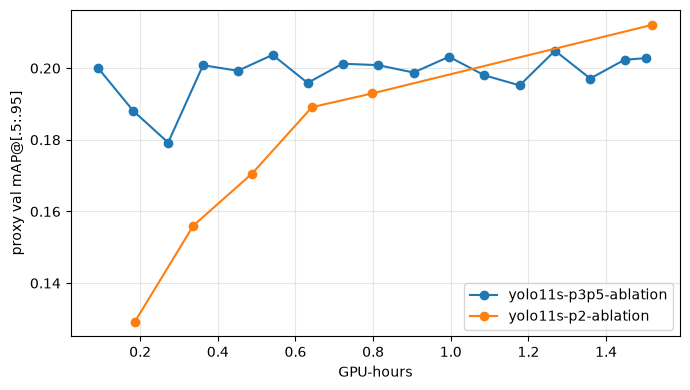

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
for rid in ARMS:
    log = training_log(rid)
    ax.plot(log["gpu_time_h"], log["val_AP"], marker="o", label=rid)
ax.set_xlabel("GPU-hours"); ax.set_ylabel("proxy val mAP@[.5:.95]"); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

## 5. Recall by object size (same-class IoU ≥ 0.5, score ≥ 0.3; √area in original px)

In [8]:
import numpy as np
from vdet.data.manifest import load_boxes
from vdet.temporal.linking import pairwise_iou_xywh

gt = load_boxes(split="val")
BANDS = [0, 12, 16, 24, 32, 64, 1e9]

def recall_by_band(preds, score_thr=0.3):
    preds = preds[preds["score"] >= score_thr]
    by_key = {k: g for k, g in preds.groupby("image_key")}
    parts = []
    for key, g in gt.groupby("image_key"):
        hit = np.zeros(len(g), dtype=bool)
        p = by_key.get(key)
        if p is not None:
            for c in g["cls"].unique():
                gm = (g["cls"] == c).to_numpy()
                pm = p[p["cls"] == c]
                if len(pm):
                    iou = pairwise_iou_xywh(g.loc[gm, ["x", "y", "w", "h"]].to_numpy(float), pm[["x", "y", "w", "h"]].to_numpy(float))
                    hit[gm] = iou.max(axis=1) >= 0.5
        parts.append(pd.DataFrame({"side": np.sqrt(g["w"] * g["h"]).to_numpy(), "hit": hit}))
    h = pd.concat(parts)
    return h.groupby(pd.cut(h["side"], BANDS), observed=True)["hit"].mean()

rec = {rid: recall_by_band(pd.read_parquet(P.runs / rid / "preds_val.parquet")) for rid in ["yolo-e1"] + ARMS}
rec = pd.DataFrame(rec)
rec.insert(0, "GT boxes", pd.cut(np.sqrt(gt["w"] * gt["h"]), BANDS).value_counts().sort_index().to_numpy())
display(rec.round(3))

,GT boxes,yolo-e1,yolo11s-p3p5-ablation,yolo11s-p2-ablation
side,,,,
"(0.0, 12.0]",162,0.000,0.000,0.000
"(12.0, 16.0]",263,0.091,0.042,0.019
"(16.0, 24.0]",7443,0.228,0.216,0.191
"(24.0, 32.0]",14063,0.350,0.351,0.383
"(32.0, 64.0]",52629,0.408,0.458,0.447
"(64.0, 1000000000.0]",39572,0.659,0.693,0.696


**Notes.** Equal 1.5 GPU-h: the P2 arm completes 6 epochs vs 17 for the control (4× more prediction cells; 37 vs 53 FPS). P2 − control: AP +0.005, AP_small +0.008, AR500 +0.061, AP_large +0.088, AP_medium −0.011. Recall of boxes ≤ 24 px is not higher (12–16 px: 0.019 vs 0.042; 16–24 px: 0.191 vs 0.216); it is higher in the 24–32 px band (0.383 vs 0.351). One run (seed 42) per arm; the small AP difference was not tested for significance.